# Main figures

The paper-style main figures of the selection and the final structure, regenerated from the saved results of `OUT`:

| file | figure |
|---|---|
| `figures/paper/fig1_workflow` | paper Fig. 1: workflow of the automated reduction with the metrics of every model |
| `figures/paper/fig2_characterization` | paper Fig. 2 (a to h): sensitivities, parameter values, parity, confidence coefficients, bootstrap, profiles |
| `figures/fig2_composite` | composite overview: influence, stage-0 against final values, parity of fit and LOOCV, CVs, bootstrap, profile |
| `figures/landscape` | multistart distribution, objective along the reduction, all profiles, bootstrap objective against KO18 copies |
| `figures/pipeline_diagram` | flow diagram of the selection procedure with the numbers of the run |
| `figures/fixing_path` | each fixed parameter by step and rule, free count, objective and rank diagnostics along the path |

Every figure is written out in full in its own cell (no plotting helpers, no loops over figures or axes), so each can be edited on its own. Numbers in the texts of the schematic figures (how many parameters each rule fixed, the objective at each stage, which parameters are identifiable) are read from the results, not typed. The figures need the outputs of the earlier steps: `parameter_selection`, `final_fit`, `bootstrap`, `profiles`, `loocv` and `figure_data` (run order in `notebooks/README.md`). They are saved as PNG and PDF unless `OUT` is one of the frozen result folders.

In [1]:
import os
import sys
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import check_out_dir, resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.RUN["out_dir"])   # default: out_dir of settings/run.csv; relative paths are relative to the repo root
RUN = os.environ.get("HK_RUN", "0") == "1"

try:
    check_out_dir(OUT)
    WRITABLE = True
except ValueError:
    WRITABLE = False

if RUN and not WRITABLE:
    raise ValueError("HK_RUN=1 refuses an output directory inside results/, results_v2/ or results_v3/: %s" % OUT)

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("REPO     :", REPO)
print("OUT      :", OUT)
print("RUN      :", RUN, "(False = load the saved results of OUT; True = compute and save into OUT)")
print("WRITABLE :", WRITABLE, "(tables / figures / report are written to OUT only if True)")

import json
import re

import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch, Rectangle, FancyBboxPatch, Polygon
from cycler import cycler

import paper_style as S
from settings import THRESHOLDS, BOUNDS_RULES
from model.parameters import ALL_PARAMS, LI_FLUX_KEYS
from data import measured_balanced_keys
from metrics import lr_threshold

FIG = os.path.join(OUT, "figures")
PAPER = os.path.join(FIG, "paper")
DATA = os.path.join(OUT, "paper_figs_data")
if WRITABLE:
    os.makedirs(PAPER, exist_ok=True)

REPO     : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733
OUT      : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model
RUN      : False (False = load the saved results of OUT; True = compute and save into OUT)
WRITABLE : True (tables / figures / report are written to OUT only if True)


## Inputs

The tables the figures read. A missing file stops here with the name of the step that writes it.

In [2]:
needed = {
    "stage0/theta_full.csv": "parameter_selection", "stage0/multistart_recorded.csv": "parameter_selection",
    "stage0/stage_row.json": "parameter_selection", "reduction/iterations.csv": "parameter_selection",
    "reduction/fixing_log.csv": "parameter_selection", "reduction/reduction.log": "parameter_selection",
    "final/final_structure.csv": "final_fit", "final/final_summary.json": "final_fit", "final/theta_full.csv": "final_fit",
    "final/pred_insample_predicted.csv": "final_fit", "final/pred_insample_real.csv": "final_fit",
    "bootstrap/bootstrap_theta.csv": "bootstrap", "bootstrap/bootstrap_resamples.csv": "bootstrap",
    "bootstrap/bootstrap_summary.csv": "bootstrap", "bootstrap/bootstrap_info.json": "bootstrap",
    "profiles/profiles_all.csv": "profiles", "profiles/profile_summary.csv": "profiles", "profiles/profile_thresholds.json": "profiles",
    "loocv/loocv_pred.csv": "loocv", "loocv/loocv_real.csv": "loocv", "loocv/fold_status.csv": "loocv",
    "paper_figs_data/stage_metrics.csv": "figure_data (after loocv)", "paper_figs_data/sens_rel_by_condition.csv": "figure_data (HK_RUN=1)",
    "paper_figs_data/y_final_inner.csv": "figure_data (HK_RUN=1)", "paper_figs_data/y_literature_inner.csv": "figure_data (HK_RUN=1)",
}
absent = {f: step for f, step in needed.items() if not os.path.exists(os.path.join(OUT, f))}
if absent:
    raise FileNotFoundError("missing results of earlier steps (run them first):\n" + "\n".join("  %-45s written by %s" % (f, s) for f, s in absent.items()))

In [3]:
def path(*parts):
    return os.path.join(OUT, *parts)

final_structure = pd.read_csv(path("final", "final_structure.csv"))
final_summary = json.load(open(path("final", "final_summary.json")))
stage_row = json.load(open(path("stage0", "stage_row.json")))
iterations = pd.read_csv(path("reduction", "iterations.csv"))
fix_log = pd.read_csv(path("reduction", "fixing_log.csv"))
profile_summary = pd.read_csv(path("profiles", "profile_summary.csv"), index_col=0)
profile_thr = json.load(open(path("profiles", "profile_thresholds.json")))
profiles_all = pd.read_csv(path("profiles", "profiles_all.csv"))
boot_info = json.load(open(path("bootstrap", "bootstrap_info.json")))
folds = pd.read_csv(path("loocv", "fold_status.csv"))
stage_metrics = pd.read_csv(path("paper_figs_data", "stage_metrics.csv"), index_col=0)
literature = pd.read_csv(os.path.join(REPO, "Data", "theta_init_sampled.csv"), index_col=0)["value"]

FREE = [p for p in ALL_PARAMS if p in set(final_structure.loc[final_structure["status"] == "free", "param"])]
CLASS_OF = S.classes_of_free(final_structure, profile_summary)
rule_counts = fix_log.groupby("rule").size().to_dict()

def n_rule(*names):
    """Number of parameters fixed by the rules ``names``."""
    return int(sum(rule_counts.get(n, 0) for n in names))

nuisance = [p for p in FREE if CLASS_OF[p] == "nuisance (kept by rule)"]
identifiable = [p for p in FREE if CLASS_OF[p] == "identifiable"]
print("free (%d): %s" % (len(FREE), FREE))
print("identifiable: %s | nuisance: %s" % (identifiable, nuisance))
print("fixed by rule:", rule_counts)

free (11): ['K_g6p_1', 'Ks_g6p_pgi', 'kcat_f_2', 'kcat_f_3', 'Ks_fbp_4', 'kcat_f_4', 'kcat_f_5', 'kcat_f_6', 'kcat_f_7', 'kcat_f_8', 'kcat_f_9']
identifiable: ['kcat_f_4', 'kcat_f_9'] | nuisance: ['K_g6p_1', 'kcat_f_3', 'kcat_f_6', 'kcat_f_7']
fixed by rule: {'corr': 1, 'flag': 1, 'structural_exact': 8, 'structural_output': 10, 'structural_pointdep': 1, 'svd': 5}


## Fig. 1: workflow of the reduction

The boxes are the models (literature reference, initial estimation with 37 free parameters, the model after the structural round, the final model) with their metrics, the hexagons the two stages of the reduction with the number of parameters each fixed, and the right-hand column the characterization of the final model: LOOCV, bootstrap and profile likelihood.

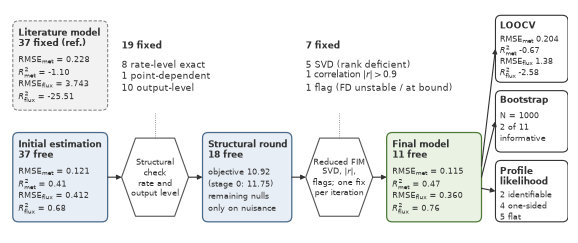

In [4]:
plt.rcdefaults()
plt.rcParams.update(S.RC)

m = stage_metrics
n_prof = profile_summary["class_lr"].value_counts()
n_struct = int(fix_log["stage"].eq("structural").sum()) if "stage" in fix_log.columns else int((fix_log["iter"] == 0).sum())
n_pract = len(fix_log) - n_struct
obj_after_struct = float(iterations.loc[iterations["iter"] == 0, "obj_after"].iloc[0])

def metric_lines(stage):
    r = m.loc[stage]
    return ("RMSE$_{\\mathrm{met}}$ = %.3f\n$R^2_{\\mathrm{met}}$ = %.2f\nRMSE$_{\\mathrm{flux}}$ = %.3f\n"
            "$R^2_{\\mathrm{flux}}$ = %.2f" % (r["rmse_met"], r["r2_met_permean"], r["rmse_flux_li"], r["r2_flux_li_permean"]))

ROUND = "round,pad=0,rounding_size=1.0"
ARROW = dict(arrowstyle="-|>", color=S.INK, lw=0.8, shrinkA=0, shrinkB=0, mutation_scale=7)
TITLE = dict(fontsize=6.2, fontweight="bold", va="top", ha="left", color=S.INK, linespacing=1.2)
BODY = dict(fontsize=6.0, va="top", ha="left", color=S.INK, linespacing=1.45)
HEX = dict(fontsize=5.9, va="center", ha="center", color=S.INK, linespacing=1.3)
C_BOX = ("#E8EEF5", "#4A6A8A")
C_LIT = ("#F2F2F2", "#888888")
C_HEX = ("#FFFFFF", "#555555")
C_FINAL = ("#EAF2E3", "#4F7A3A")

fig, ax = plt.subplots(figsize=(7.2, 2.9))
ax.set_xlim(0, 100)
ax.set_ylim(0, 40)
ax.axis("off")

# ---- literature reference (no arrow: not a starting point of the reduction) ----
ax.add_patch(FancyBboxPatch((0.5, 22), 17, 16, boxstyle=ROUND, fc=C_LIT[0], ec=C_LIT[1], lw=0.8, ls=(0, (3, 1.5))))
ax.text(1.5, 37.0, "Literature model\n37 fixed (ref.)", **TITLE)
ax.text(1.5, 32.0, metric_lines("literature"), **BODY)

# ---- stage 0 ----
ax.add_patch(FancyBboxPatch((0.5, 2), 17, 16, boxstyle=ROUND, fc=C_BOX[0], ec=C_BOX[1], lw=0.9))
ax.text(1.5, 17.0, "Initial estimation\n37 free", **TITLE)
ax.text(1.5, 12.0, metric_lines("stage0"), **BODY)

# ---- hexagon 1: structural check ----
ax.annotate("", xy=(20, 10), xytext=(17.5, 10), arrowprops=ARROW)
ax.add_patch(Polygon([(20, 10), (22.5, 17), (29.5, 17), (32, 10), (29.5, 3), (22.5, 3)], closed=True, fc=C_HEX[0], ec=C_HEX[1], lw=0.8))
ax.text(26, 10, "Structural\ncheck\nrate and\noutput level", **HEX)
ax.plot([26, 26], [17, 21.5], color=S.MUTED, lw=0.6, ls=":")
ax.text(20, 34.5, "%d fixed" % n_struct, fontsize=6.6, fontweight="bold", va="top", ha="left", color=S.INK)
ax.text(20, 31.4, "%d rate-level exact\n%d point-dependent\n%d output-level" % (
    n_rule("structural_exact", "structural_mixed"), n_rule("structural_pointdep"), n_rule("structural_output")),
    fontsize=6.2, va="top", ha="left", color=S.INK, linespacing=1.4)

# ---- after the structural round ----
ax.annotate("", xy=(34.5, 10), xytext=(32, 10), arrowprops=ARROW)
ax.add_patch(FancyBboxPatch((34.5, 2), 16, 16, boxstyle=ROUND, fc=C_BOX[0], ec=C_BOX[1], lw=0.9))
ax.text(35.5, 17.0, "Structural round\n%d free" % (len(ALL_PARAMS) - n_struct), **TITLE)
ax.text(35.5, 12.0, "objective %.2f\n(stage 0: %.2f)\nremaining nulls\nonly on nuisance" % (obj_after_struct, stage_row["obj"]), **BODY)

# ---- hexagon 2: practical rules ----
ax.annotate("", xy=(53, 10), xytext=(50.5, 10), arrowprops=ARROW)
ax.add_patch(Polygon([(53, 10), (55.5, 17), (62.5, 17), (65, 10), (62.5, 3), (55.5, 3)], closed=True, fc=C_HEX[0], ec=C_HEX[1], lw=0.8))
ax.text(59, 10, "Reduced FIM\nSVD, $|r|$,\nflags; one fix\nper iteration", **HEX)
ax.plot([59, 59], [17, 21.5], color=S.MUTED, lw=0.6, ls=":")
ax.text(53, 34.5, "%d fixed" % n_pract, fontsize=6.6, fontweight="bold", va="top", ha="left", color=S.INK)
pract_lines = [txt % n for txt, n in (("%d zero influence", n_rule("zero_influence")), ("%d SVD (rank deficient)", n_rule("svd")),
                                      ("%d correlation $|r| > " + "%g$" % THRESHOLDS["corr_threshold"], n_rule("corr")),
                                      ("%d flag (FD unstable / at bound)", n_rule("flag"))) if n]
ax.text(53, 31.4, "\n".join(pract_lines), fontsize=6.2, va="top", ha="left", color=S.INK, linespacing=1.4)

# ---- final reduced model ----
ax.annotate("", xy=(67.5, 10), xytext=(65, 10), arrowprops=ARROW)
ax.add_patch(FancyBboxPatch((67.5, 2), 17, 16, boxstyle=ROUND, fc=C_FINAL[0], ec=C_FINAL[1], lw=0.9))
ax.text(68.5, 17.0, "Final model\n%d free" % len(FREE), **TITLE)
ax.text(68.5, 12.0, metric_lines("final"), **BODY)

# ---- characterization ----
ax.annotate("", xy=(87, 33), xytext=(84.5, 12), arrowprops=ARROW)
ax.annotate("", xy=(87, 20), xytext=(84.5, 10), arrowprops=ARROW)
ax.annotate("", xy=(87, 7.5), xytext=(84.5, 8), arrowprops=ARROW)
ax.add_patch(FancyBboxPatch((87, 27), 13, 12, boxstyle=ROUND, fc="#FFFFFF", ec=S.INK, lw=0.8))
ax.text(87.8, 38.2, "LOOCV", **TITLE)
ax.text(87.8, 35.6, "RMSE$_{\\mathrm{met}}$ %.3f\n$R^2_{\\mathrm{met}}$ %.2f\nRMSE$_{\\mathrm{flux}}$ %.2f\n"
        "$R^2_{\\mathrm{flux}}$ %.2f" % (m.loc["loocv", "rmse_met"], m.loc["loocv", "r2_met_permean"],
                                         m.loc["loocv", "rmse_flux_li"], m.loc["loocv", "r2_flux_li_permean"]),
        fontsize=5.7, va="top", ha="left", color=S.INK, linespacing=1.4)
ax.add_patch(FancyBboxPatch((87, 14.5), 13, 11, boxstyle=ROUND, fc="#FFFFFF", ec=S.INK, lw=0.8))
ax.text(87.8, 24.7, "Bootstrap", **TITLE)
ax.text(87.8, 22.1, "N = %d\n%d of %d\ninformative" % (boot_info["n_resamples"], len(identifiable), len(FREE)), fontsize=5.7,
        va="top", ha="left", color=S.INK, linespacing=1.4)
ax.add_patch(FancyBboxPatch((87, 2), 13, 11, boxstyle=ROUND, fc="#FFFFFF", ec=S.INK, lw=0.8))
ax.text(87.8, 12.2, "Profile\nlikelihood", **TITLE)
ax.text(87.8, 8.0, "%d identifiable\n%d one-sided\n%d flat" % (n_prof.get("identifiable", 0), n_prof.get("one_sided", 0), n_prof.get("flat", 0)),
        fontsize=5.7, va="top", ha="left", color=S.INK, linespacing=1.4)

if WRITABLE:
    fig.savefig(os.path.join(PAPER, "fig1_workflow.png"), bbox_inches="tight")
    fig.savefig(os.path.join(PAPER, "fig1_workflow.pdf"), bbox_inches="tight")

plt.show()

## Fig. 2: characterization of the final model

a) mean relative reduced sensitivity $|\partial\ln y/\partial\ln\theta|$ of the measured outputs to the free parameters (entries where the output is below 1% of its median are excluded because the relative sensitivity diverges); b) parameter values: literature, initial estimation, final; c) and d) parity of the LI fluxes and of the metabolites (log-log) for the literature model, the final fit and LOOCV; e) bootstrap confidence coefficient (BC 95% interval width over the estimate) by class; f) bootstrap distribution of the best-determined parameter; g) bootstrap objective stacked by the number of KO18 copies; h) profile likelihood of the best-determined parameter against a flat one.

In [5]:
def mean_abs_ignoring_nan(values):
    return float(np.nanmean(np.abs(values)))

# ---- data for the panels ----
sens = pd.read_csv(path("paper_figs_data", "sens_rel_by_condition.csv"))
y0 = pd.read_csv(path("paper_figs_data", "y_final_inner.csv"), index_col=0)
free = FREE
keep = []
for _, r in sens.iterrows():
    col = y0[r["output"]].abs()
    keep.append(abs(y0.loc[r["condition"], r["output"]]) >= 0.01 * col.median())

sens = sens[np.array(keep)]
n_excluded = int((~np.array(keep)).sum())
mean_abs = sens.groupby("output")[free].agg(mean_abs_ignoring_nan)
rows_met = measured_balanced_keys()
rows_flux = list(LI_FLUX_KEYS)
H = mean_abs.reindex(rows_met + rows_flux)[free].to_numpy(float)
H = np.where(H > 0, H, np.nan)
row_labels = [S.METABOLITE_LABEL[k] for k in rows_met] + ["$v$ " + S.FLUX_LABEL[k] for k in rows_flux]
col_labels = [S.label(p) for p in free]
col_rxn = [S.reaction_of(p) for p in free]

th0 = pd.read_csv(path("stage0", "theta_full.csv"), index_col=0)["value"]
thf = pd.read_csv(path("final", "theta_full.csv"), index_col=0)["value"]
v_lit = np.array([literature[p] for p in free], float)
v_0 = np.array([th0[p] for p in free], float)
v_f = np.array([thf[p] for p in free], float)

real = pd.read_csv(path("final", "pred_insample_real.csv"), index_col=0)
pred_f = pd.read_csv(path("final", "pred_insample_predicted.csv"), index_col=0).reindex(index=real.index, columns=real.columns)
pred_l = pd.read_csv(path("loocv", "loocv_pred.csv"), index_col=0).reindex(index=real.index, columns=real.columns)
pred_lit = pd.read_csv(path("paper_figs_data", "y_literature_inner.csv"), index_col=0).reindex(index=real.index, columns=real.columns)
met_cols = [c for c in rows_met if c in real.columns]
m = stage_metrics

def pairs(pred, cols):
    yr = real[cols].to_numpy(float).ravel()
    yp = pred[cols].to_numpy(float).ravel()
    ok = np.isfinite(yr) & np.isfinite(yp)
    return yp[ok], yr[ok]

fx_lit, fy_lit = pairs(pred_lit, LI_FLUX_KEYS)
fx_f, fy_f = pairs(pred_f, LI_FLUX_KEYS)
fx_l, fy_l = pairs(pred_l, LI_FLUX_KEYS)
mx_lit, my_lit = pairs(pred_lit, met_cols)
mx_f, my_f = pairs(pred_f, met_cols)
mx_l, my_l = pairs(pred_l, met_cols)

boot = pd.read_csv(path("bootstrap", "bootstrap_theta.csv"))
boot = boot[boot["converged"]].reset_index(drop=True)
res = pd.read_csv(path("bootstrap", "bootstrap_resamples.csv")).set_index("resample")
n_ko18 = np.array([names.split(";").count("KO18") for names in res.loc[boot["resample"], "conditions"]])
cc = {}
ci = {}
for p in free:
    th = float(thf[p])
    tb = boot[p].to_numpy(float)
    z0 = scipy.stats.norm.ppf(np.clip(np.mean(tb < th), 1e-12, 1 - 1e-12))
    a1 = scipy.stats.norm.cdf(2 * z0 + scipy.stats.norm.ppf(0.025))
    a2 = scipy.stats.norm.cdf(2 * z0 + scipy.stats.norm.ppf(0.975))
    lo, hi = np.percentile(tb, 100 * a1), np.percentile(tb, 100 * a2)
    ci[p] = (lo, hi)
    cc[p] = (hi - lo) / th

e_params, e_y, y_now = [], [], 0.0
class_first_y = {}
for cls in S.CLASSES:
    members = [q for q in free if CLASS_OF[q] == cls]
    if members:
        class_first_y[cls] = y_now
    for p in members:
        e_params.append(p)
        e_y.append(y_now)
        y_now += 1.0
    y_now += 0.5

e_y = np.array(e_y)
e_vals = np.array([max(cc[p], 1.5e-4) for p in e_params])
e_colors = [S.CLASS_COLOR[CLASS_OF[p]] for p in e_params]

best_param = min(identifiable, key=cc.get) if identifiable else free[0]
flat_candidates = [p for p in free if profile_summary.loc[p, "class_lr"] == "flat" and p != best_param]
flat_param = next((p for p in flat_candidates if CLASS_OF[p] == "poorly determined"), flat_candidates[0] if flat_candidates else free[-1])
kb = boot[best_param].to_numpy(float)
ci_w = ci[best_param][1] - ci[best_param][0]
kb_lo, kb_hi = ci[best_param][0] - 0.35 * ci_w, ci[best_param][1] + 0.5 * ci_w
kb_bins = np.linspace(kb_lo, kb_hi, 49)
kb_out = float(np.mean((kb < kb_lo) | (kb > kb_hi)))
obj = boot["obj"].to_numpy(float)
obj_bins = np.linspace(0, np.percentile(obj, 99.5), 50)
obj_groups = [obj[n_ko18 == 0], obj[n_ko18 == 1], obj[n_ko18 == 2], obj[n_ko18 >= 3]]
obj_labels = ["0 (n=%d)" % len(obj_groups[0]), "1 (n=%d)" % len(obj_groups[1]), "2 (n=%d)" % len(obj_groups[2]), "3+ (n=%d)" % len(obj_groups[3])]
obj_colors = ["#cde2fb", "#86b6ef", "#2a78d6", "#104281"]

obj_hat = float(profile_thr["obj_hat"])
lr = float(profile_thr["lr_threshold_0.95"])
p_best = profiles_all[profiles_all["param"] == best_param].sort_values("log10_offset")
p_flat = profiles_all[profiles_all["param"] == flat_param].sort_values("log10_offset")
print("panels f and h use %s (best determined) and %s (flat)" % (best_param, flat_param))

panels f and h use kcat_f_4 (best determined) and Ks_g6p_pgi (flat)


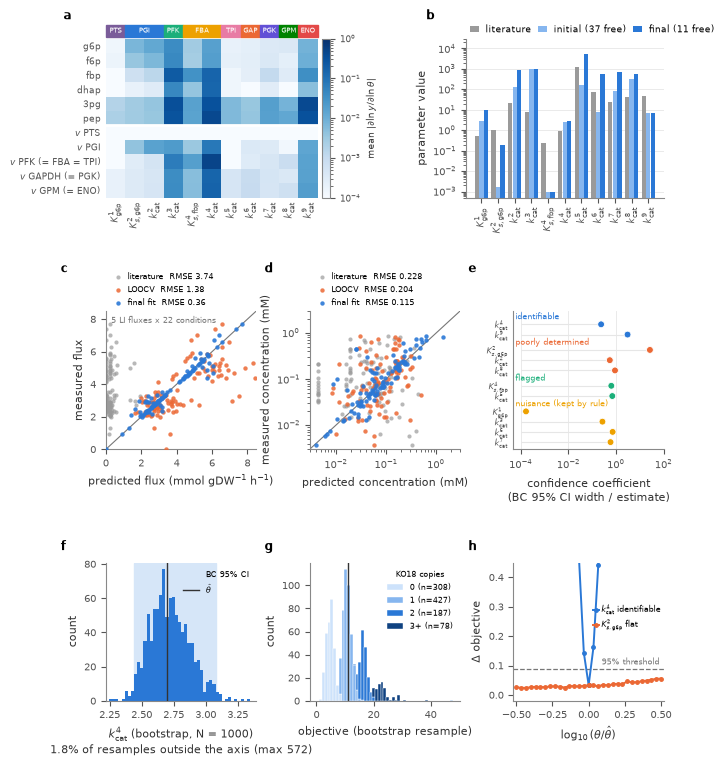

sensitivity entries excluded (|y| < 1% of the output median): 1
confidence coefficients: {'K_g6p_1': np.float64(0.0), 'Ks_g6p_pgi': np.float64(26.04), 'kcat_f_2': np.float64(0.543), 'kcat_f_3': np.float64(0.267), 'Ks_fbp_4': np.float64(0.629), 'kcat_f_4': np.float64(0.235), 'kcat_f_5': np.float64(0.691), 'kcat_f_6': np.float64(0.714), 'kcat_f_7': np.float64(0.583), 'kcat_f_8': np.float64(0.897), 'kcat_f_9': np.float64(3.013)}


In [6]:
plt.rcdefaults()
plt.rcParams.update(S.RC)

fig = plt.figure(figsize=(7.2, 8.6))
gs = fig.add_gridspec(3, 6, height_ratios=[1.15, 1.0, 1.0], hspace=0.78, wspace=1.1)
gs_top = gs[0, :].subgridspec(1, 2, width_ratios=[1.15, 1.0], wspace=0.62)
ax_a = fig.add_subplot(gs_top[0, 0])
ax_b = fig.add_subplot(gs_top[0, 1])
ax_c = fig.add_subplot(gs[1, 0:2])
ax_d = fig.add_subplot(gs[1, 2:4])
ax_e = fig.add_subplot(gs[1, 4:6])
ax_f = fig.add_subplot(gs[2, 0:2])
ax_g = fig.add_subplot(gs[2, 2:4])
ax_h = fig.add_subplot(gs[2, 4:6])

# ---- (a) sensitivity heatmap ----
im = ax_a.imshow(H, aspect="auto", cmap="Blues", norm=LogNorm(vmin=1e-4, vmax=1.0))
ax_a.set_facecolor("#f2f2f2")
ax_a.set_xticks(range(len(free)))
ax_a.set_xticklabels(col_labels, rotation=90, fontsize=6.8)
ax_a.set_yticks(range(len(row_labels)))
ax_a.set_yticklabels(row_labels, fontsize=6.6)
ax_a.axhline(len(rows_met) - 0.5, color="white", lw=2.0)
for j, r in enumerate(col_rxn):
    ax_a.add_patch(Rectangle((j - 0.5, -1.45), 1.0, 0.8, color=S.REACTION_COLOR[r - 1], clip_on=False))

for r in sorted(set(col_rxn)):
    cols_r = [j for j, rr in enumerate(col_rxn) if rr == r]
    ax_a.text(float(np.mean(cols_r)), -1.05, S.REACTIONS[r - 1][:3], ha="center", va="center", fontsize=5.2, color="white", clip_on=False)

ax_a.set_ylim(len(row_labels) - 0.5, -0.5)
ax_a.tick_params(length=0)
for sp in ax_a.spines.values():
    sp.set_visible(False)

cb = fig.colorbar(im, ax=ax_a, fraction=0.05, pad=0.02)
cb.set_label("mean $|\\partial \\ln y / \\partial \\ln \\theta|$", fontsize=6.8)
cb.ax.tick_params(labelsize=6.2)
ax_a.set_title("a", fontweight="bold", x=-0.2, y=1.07)

# ---- (b) parameter values per stage ----
xb = np.arange(len(free))
ax_b.bar(xb - 0.27, v_lit, width=0.26, color=S.STAGE_COLOR["literature"], label="literature")
ax_b.bar(xb, v_0, width=0.26, color=S.STAGE_COLOR["stage0"], label="initial (37 free)")
ax_b.bar(xb + 0.27, v_f, width=0.26, color=S.STAGE_COLOR["final"], label="final (%d free)" % len(free))
ax_b.set_yscale("log")
ax_b.set_ylim(5e-4, 3e4)
ax_b.set_xticks(xb)
ax_b.set_xticklabels(col_labels, rotation=90, fontsize=6.8)
ax_b.set_ylabel("parameter value")
ax_b.grid(axis="y", color=S.GRID, lw=0.6)
ax_b.set_axisbelow(True)
ax_b.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), frameon=False, ncol=3, handlelength=1.0, columnspacing=0.8, fontsize=6.2, borderaxespad=0.1)
ax_b.set_title("b", fontweight="bold", x=-0.2, y=1.07)

# ---- (c) LI flux parity ----
ax_c.plot([0, 8.5], [0, 8.5], color=S.MUTED, lw=0.8, zorder=1)
ax_c.scatter(fx_lit, fy_lit, s=9, color=S.STAGE_COLOR["literature"], alpha=0.7, lw=0, zorder=2, label="literature  RMSE %.2f" % m.loc["literature", "rmse_flux_li"])
ax_c.scatter(fx_l, fy_l, s=10, color=S.STAGE_COLOR["loocv"], alpha=0.85, lw=0, zorder=3, label="LOOCV  RMSE %.2f" % m.loc["loocv", "rmse_flux_li"])
ax_c.scatter(fx_f, fy_f, s=10, color=S.STAGE_COLOR["final"], alpha=0.9, lw=0, zorder=4, label="final fit  RMSE %.2f" % m.loc["final", "rmse_flux_li"])
ax_c.set_xlim(0, 8.5)
ax_c.set_ylim(0, 8.5)
ax_c.set_xlabel("predicted flux (mmol gDW$^{-1}$ h$^{-1}$)")
ax_c.set_ylabel("measured flux")
ax_c.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), frameon=False, fontsize=5.8, handletextpad=0.2, borderaxespad=0.1)
ax_c.set_title("c", fontweight="bold", x=-0.3, y=1.22)
ax_c.text(0.3, 8.2, "5 LI fluxes x 22 conditions", ha="left", va="top", fontsize=5.8, color=S.MUTED)

# ---- (d) metabolite parity (log-log) ----
ax_d.plot([3e-3, 3], [3e-3, 3], color=S.MUTED, lw=0.8, zorder=1)
ax_d.scatter(mx_lit, my_lit, s=9, color=S.STAGE_COLOR["literature"], alpha=0.7, lw=0, zorder=2, label="literature  RMSE %.3f" % m.loc["literature", "rmse_met"])
ax_d.scatter(mx_l, my_l, s=10, color=S.STAGE_COLOR["loocv"], alpha=0.85, lw=0, zorder=3, label="LOOCV  RMSE %.3f" % m.loc["loocv", "rmse_met"])
ax_d.scatter(mx_f, my_f, s=10, color=S.STAGE_COLOR["final"], alpha=0.9, lw=0, zorder=4, label="final fit  RMSE %.3f" % m.loc["final", "rmse_met"])
ax_d.set_xscale("log")
ax_d.set_yscale("log")
ax_d.set_xlim(3e-3, 3)
ax_d.set_ylim(3e-3, 3)
ax_d.set_xlabel("predicted concentration (mM)")
ax_d.set_ylabel("measured concentration (mM)")
ax_d.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), frameon=False, fontsize=5.8, handletextpad=0.2, borderaxespad=0.1)
ax_d.set_title("d", fontweight="bold", x=-0.3, y=1.22)

# ---- (e) confidence coefficient per free parameter, grouped by class ----
ax_e.scatter(e_vals, e_y, s=24, c=e_colors, edgecolors="white", linewidths=0.6, zorder=3)
ax_e.hlines(e_y, 1e-4, e_vals, color=S.GRID, lw=0.8, zorder=1)
ax_e.set_xscale("log")
ax_e.set_xlim(5e-5, 1e2)
ax_e.set_yticks(e_y)
ax_e.set_yticklabels([S.label(p) for p in e_params], fontsize=5.6)
ax_e.set_ylim(e_y.max() + 0.7, -1.3)
for cls, y_first in class_first_y.items():
    ax_e.text(6e-5, y_first - 0.75, cls, ha="left", va="center", fontsize=5.8, color=S.CLASS_COLOR[cls])

ax_e.set_xlabel("confidence coefficient\n(BC 95% CI width / estimate)")
ax_e.grid(axis="x", color=S.GRID, lw=0.6)
ax_e.tick_params(axis="y", length=0)
ax_e.set_title("e", fontweight="bold", x=-0.3, y=1.22)

# ---- (f) bootstrap distribution of the best-determined parameter ----
ax_f.axvspan(ci[best_param][0], ci[best_param][1], color="#d6e6f8", zorder=0, label="BC 95% CI")
ax_f.hist(kb, bins=kb_bins, color=S.CLASS_COLOR["identifiable"], zorder=2)
ax_f.axvline(float(thf[best_param]), color=S.INK, lw=1.0, zorder=3, label="$\\hat{\\theta}$")
ax_f.set_xlim(kb_lo, kb_hi)
ax_f.set_xlabel(S.label(best_param) + " (bootstrap, N = %d)\n%.1f%% of resamples outside the axis (max %.0f)" % (len(kb), 100 * kb_out, kb.max()))
ax_f.set_ylabel("count")
ax_f.legend(loc="upper right", frameon=False, fontsize=6.0)
ax_f.set_title("f", fontweight="bold", x=-0.3, y=1.03)

# ---- (g) bootstrap objective by KO18 copies ----
ax_g.hist(obj_groups, bins=obj_bins, stacked=True, color=obj_colors, label=obj_labels, edgecolor="white", linewidth=0.3)
ax_g.axvline(float(final_summary["obj"]), color=S.INK, lw=1.0)
ax_g.set_xlabel("objective (bootstrap resample)")
ax_g.set_ylabel("count")
ax_g.legend(loc="upper right", frameon=False, fontsize=5.8, title="KO18 copies", title_fontsize=6.0)
ax_g.set_title("g", fontweight="bold", x=-0.3, y=1.03)

# ---- (h) profile likelihood: identifiable vs flat ----
ax_h.axhline(lr, color=S.MUTED, lw=0.9, ls="--")
ax_h.text(0.49, lr + 0.01, "95% threshold", ha="right", va="bottom", fontsize=5.8, color=S.MUTED)
ax_h.plot(p_best["log10_offset"], p_best["obj"] - obj_hat, "-o", ms=2.5, lw=1.4, color=S.CLASS_COLOR["identifiable"], label=S.label(best_param) + " " + profile_summary.loc[best_param, "class_lr"].replace("_", "-"))
ax_h.plot(p_flat["log10_offset"], p_flat["obj"] - obj_hat, "-o", ms=2.5, lw=1.4, color=S.CLASS_COLOR["poorly determined"], label=S.label(flat_param) + " " + profile_summary.loc[flat_param, "class_lr"].replace("_", "-"))
ax_h.set_ylim(-0.02, 0.45)
ax_h.set_xlim(-0.52, 0.52)
ax_h.set_xlabel("$\\log_{10}(\\theta / \\hat{\\theta})$")
ax_h.set_ylabel("$\\Delta$ objective")
ax_h.legend(loc="center right", bbox_to_anchor=(1.03, 0.6), frameon=False, fontsize=5.6, handlelength=0.8, handletextpad=0.3)
ax_h.set_title("h", fontweight="bold", x=-0.3, y=1.03)

if WRITABLE:
    fig.savefig(os.path.join(PAPER, "fig2_characterization.png"), bbox_inches="tight")
    fig.savefig(os.path.join(PAPER, "fig2_characterization.pdf"), bbox_inches="tight")

plt.show()
print("sensitivity entries excluded (|y| < 1% of the output median):", n_excluded)
print("confidence coefficients:", {p: round(v, 3) for p, v in cc.items()})

## Composite overview (`fig2_composite`)

Eight panels on one page: a) influence per free parameter coloured by class, b) stage-0 against final values, c) and d) parity of the in-sample fit and of the LOOCV held-out predictions (LI fluxes, metabolites), e) CV from the Schur complement (hatched: nuisance) with the bootstrap CV, f) bootstrap distribution of `kcat_f_4`, g) bootstrap objective, h) profile likelihood of `kcat_f_4`.

In [7]:
# ---- data for the composite panels ----
free_rows = final_structure[final_structure["status"] == "free"].reset_index(drop=True)
free_names = free_rows["param"].tolist()
n_free = len(free_names)
final_vals = free_rows["value"].values.astype(float)
infl = free_rows["influence"].values.astype(float)
ident = free_rows["ident_class"].values
cv_final = free_rows["cv_percent"].values.astype(float)
kept = ident == "kept_free_by_rule"
class_colors = {"identifiable": "#2ca02c", "identifiable_by_fim": "#2ca02c", "kept_free_by_rule": "#ff7f0e", "flagged": "#d62728"}
bar_colors_a = [class_colors.get(c, "grey") for c in ident]
stage0_vals = pd.read_csv(path("stage0", "theta_full.csv")).set_index("param").loc[free_names, "value"].values.astype(float)

pred_ins = pd.read_csv(path("final", "pred_insample_predicted.csv"), index_col=0)
real_ins = pd.read_csv(path("final", "pred_insample_real.csv"), index_col=0).loc[pred_ins.index, pred_ins.columns]
pred_loo = pd.read_csv(path("loocv", "loocv_pred.csv"), index_col=0)
real_loo = pd.read_csv(path("loocv", "loocv_real.csv"), index_col=0).loc[pred_loo.index, pred_loo.columns]

flux_cols = list(LI_FLUX_KEYS)
x_ins_f, y_ins_f = pred_ins[flux_cols].values, real_ins[flux_cols].values
ok = np.isfinite(x_ins_f) & np.isfinite(y_ins_f)
x_ins_f, y_ins_f = x_ins_f[ok], y_ins_f[ok]
x_loo_f, y_loo_f = pred_loo[flux_cols].values, real_loo[flux_cols].values
ok = np.isfinite(x_loo_f) & np.isfinite(y_loo_f)
x_loo_f, y_loo_f = x_loo_f[ok], y_loo_f[ok]

met_cols_c = [c for c in pred_ins.columns if c.startswith("C_")]
x_ins_c, y_ins_c = pred_ins[met_cols_c].values, real_ins[met_cols_c].values
ok = np.isfinite(x_ins_c) & np.isfinite(y_ins_c) & (x_ins_c > 0) & (y_ins_c > 0)
x_ins_c, y_ins_c = x_ins_c[ok], y_ins_c[ok]
x_loo_c, y_loo_c = pred_loo[met_cols_c].values, real_loo[met_cols_c].values
ok = np.isfinite(x_loo_c) & np.isfinite(y_loo_c) & (x_loo_c > 0) & (y_loo_c > 0)
x_loo_c, y_loo_c = x_loo_c[ok], y_loo_c[ok]

boot_c = pd.read_csv(path("bootstrap", "bootstrap_theta.csv"))
boot_c = boot_c[boot_c["converged"].astype(bool)]
boot_sum = pd.read_csv(path("bootstrap", "bootstrap_summary.csv"), index_col=0)
cv_boot = boot_sum.loc[free_names, "cv_percent"].values.astype(float)

comp_param = "kcat_f_4" if "kcat_f_4" in free_names else best_param
k4_anchor = final_vals[free_names.index(comp_param)]
k4_boot = boot_c[comp_param].values.astype(float)
k4_p025 = float(boot_sum.loc[comp_param, "p2.5"])
k4_p975 = float(boot_sum.loc[comp_param, "p97.5"])
k4_lo, k4_hi = np.percentile(k4_boot, [1, 99])
k4_clip = np.clip(k4_boot, k4_lo, k4_hi)
k4_bins = np.linspace(k4_lo, k4_hi, 41)
obj_boot = boot_c["obj"].values.astype(float)

prof4 = profiles_all[(profiles_all["param"] == comp_param) & profiles_all["obj"].notna()].sort_values("value")
prof4_x = prof4["value"].values.astype(float)
prof4_y = prof4["obj"].values.astype(float) - profile_thr["obj_hat"]

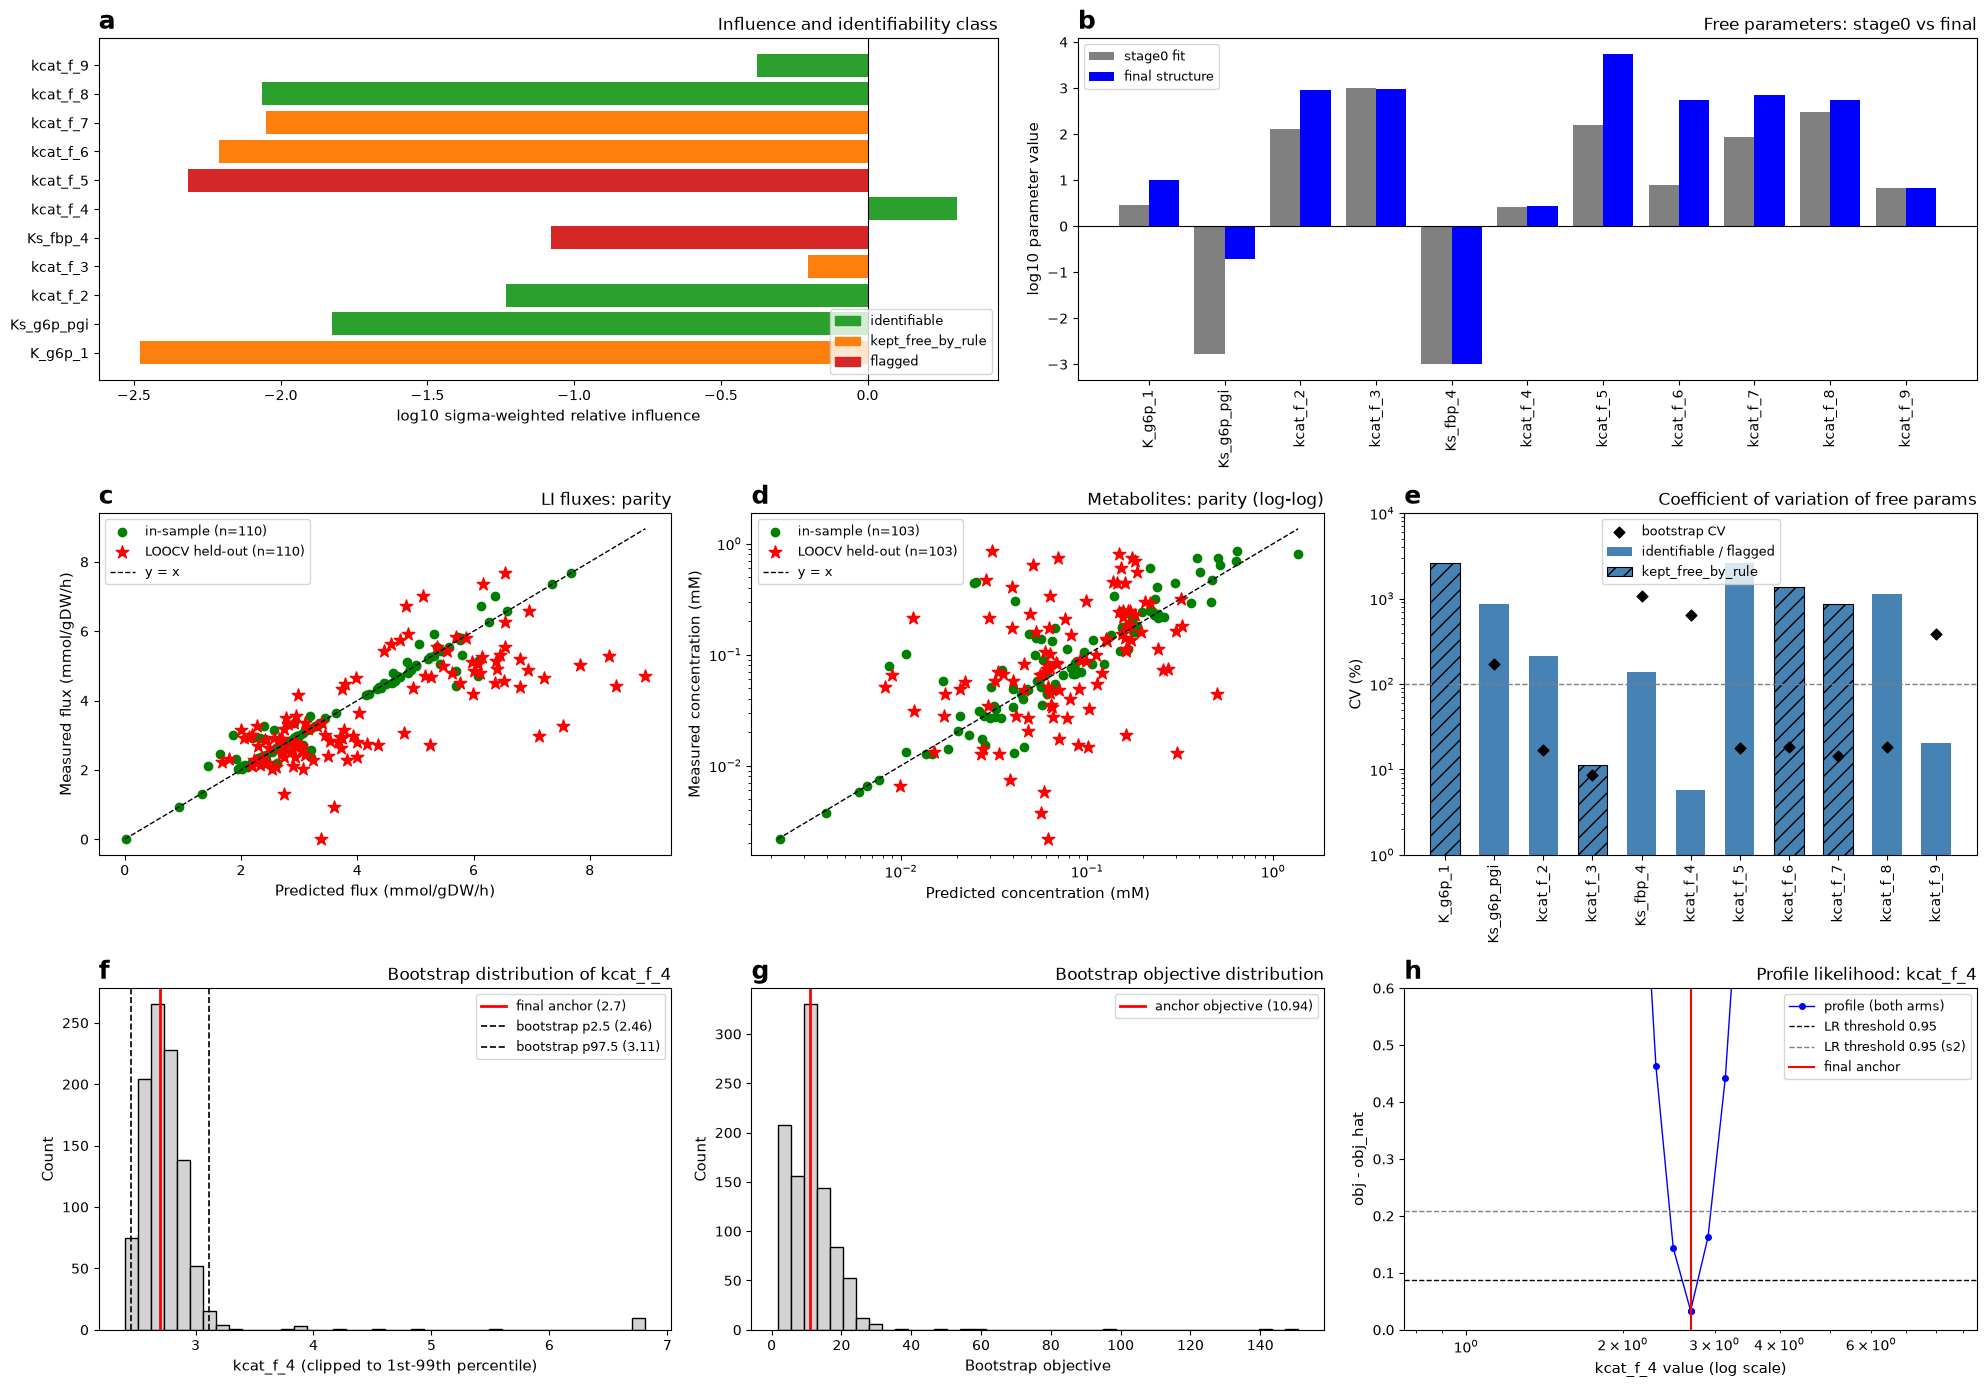

In [8]:
plt.rcdefaults()
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
                     "legend.fontsize": 9, "savefig.dpi": 200, "pdf.fonttype": 42})

fig = plt.figure(figsize=(20, 14))
gs = gridspec.GridSpec(3, 6, figure=fig)
ax_a = fig.add_subplot(gs[0, 0:3])
ax_b = fig.add_subplot(gs[0, 3:6])
ax_c = fig.add_subplot(gs[1, 0:2])
ax_d = fig.add_subplot(gs[1, 2:4])
ax_e = fig.add_subplot(gs[1, 4:6])
ax_f = fig.add_subplot(gs[2, 0:2])
ax_g = fig.add_subplot(gs[2, 2:4])
ax_h = fig.add_subplot(gs[2, 4:6])

x_a = np.arange(n_free)
ax_a.barh(x_a, np.log10(infl), color=bar_colors_a)
ax_a.set_yticks(x_a)
ax_a.set_yticklabels(free_names)
ax_a.axvline(0, color="black", lw=0.8)
ax_a.set_xlabel("log10 sigma-weighted relative influence")
ax_a.legend(handles=[Patch(color=class_colors[k], label=k) for k in ("identifiable", "kept_free_by_rule", "flagged")], loc="lower right")
ax_a.set_title("Influence and identifiability class", loc="right")
ax_a.text(0.0, 1.01, "a", transform=ax_a.transAxes, fontsize=18, fontweight="bold", ha="left", va="bottom")

x_b = np.arange(n_free)
ax_b.bar(x_b - 0.2, np.log10(stage0_vals), width=0.4, color="grey", label="stage0 fit")
ax_b.bar(x_b + 0.2, np.log10(final_vals), width=0.4, color="blue", label="final structure")
ax_b.set_xticks(x_b)
ax_b.set_xticklabels(free_names, rotation=90)
ax_b.axhline(0, color="black", lw=0.8)
ax_b.set_ylabel("log10 parameter value")
ax_b.legend(loc="upper left")
ax_b.set_title("Free parameters: stage0 vs final", loc="right")
ax_b.text(0.0, 1.01, "b", transform=ax_b.transAxes, fontsize=18, fontweight="bold", ha="left", va="bottom")

ax_c.scatter(x_ins_f, y_ins_f, marker="o", color="green", label="in-sample (n=%d)" % len(x_ins_f))
ax_c.scatter(x_loo_f, y_loo_f, marker="*", s=90, color="red", label="LOOCV held-out (n=%d)" % len(x_loo_f))
lo_c = min(x_ins_f.min(), y_ins_f.min(), x_loo_f.min(), y_loo_f.min())
hi_c = max(x_ins_f.max(), y_ins_f.max(), x_loo_f.max(), y_loo_f.max())
ax_c.plot([lo_c, hi_c], [lo_c, hi_c], "k--", lw=1, label="y = x")
ax_c.set_xlabel("Predicted flux (mmol/gDW/h)")
ax_c.set_ylabel("Measured flux (mmol/gDW/h)")
ax_c.legend(loc="upper left")
ax_c.set_title("LI fluxes: parity", loc="right")
ax_c.text(0.0, 1.01, "c", transform=ax_c.transAxes, fontsize=18, fontweight="bold", ha="left", va="bottom")

ax_d.scatter(x_ins_c, y_ins_c, marker="o", color="green", label="in-sample (n=%d)" % len(x_ins_c))
ax_d.scatter(x_loo_c, y_loo_c, marker="*", s=90, color="red", label="LOOCV held-out (n=%d)" % len(x_loo_c))
lo_d = min(x_ins_c.min(), y_ins_c.min(), x_loo_c.min(), y_loo_c.min())
hi_d = max(x_ins_c.max(), y_ins_c.max(), x_loo_c.max(), y_loo_c.max())
ax_d.plot([lo_d, hi_d], [lo_d, hi_d], "k--", lw=1, label="y = x")
ax_d.set_xscale("log")
ax_d.set_yscale("log")
ax_d.set_xlabel("Predicted concentration (mM)")
ax_d.set_ylabel("Measured concentration (mM)")
ax_d.legend(loc="upper left")
ax_d.set_title("Metabolites: parity (log-log)", loc="right")
ax_d.text(0.0, 1.01, "d", transform=ax_d.transAxes, fontsize=18, fontweight="bold", ha="left", va="bottom")

cv_plain = np.where(kept, np.nan, cv_final)
cv_kept = np.where(kept, cv_final, np.nan)
ax_e.set_yscale("log")
ax_e.bar(x_a, cv_plain, width=0.6, color="steelblue", label="identifiable / flagged")
ax_e.bar(x_a, cv_kept, width=0.6, color="steelblue", edgecolor="black", hatch="//", lw=0.8, label="kept_free_by_rule")
ax_e.scatter(x_a, cv_boot, marker="D", color="black", s=30, zorder=3, label="bootstrap CV")
ax_e.axhline(100, color="grey", ls="--", lw=1)
ax_e.set_xticks(x_a)
ax_e.set_xticklabels(free_names, rotation=90)
ax_e.set_ylim(1, 1e4)
ax_e.set_ylabel("CV (%)")
ax_e.legend(loc="upper center")
ax_e.set_title("Coefficient of variation of free params", loc="right")
ax_e.text(0.0, 1.01, "e", transform=ax_e.transAxes, fontsize=18, fontweight="bold", ha="left", va="bottom")

ax_f.hist(k4_clip, bins=k4_bins, color="lightgrey", edgecolor="black")
ax_f.axvline(k4_anchor, color="red", lw=2, label="final anchor (%.3g)" % k4_anchor)
ax_f.axvline(k4_p025, color="black", ls="--", lw=1.2, label="bootstrap p2.5 (%.3g)" % k4_p025)
ax_f.axvline(k4_p975, color="black", ls="--", lw=1.2, label="bootstrap p97.5 (%.3g)" % k4_p975)
ax_f.set_xlabel(comp_param + " (clipped to 1st-99th percentile)")
ax_f.set_ylabel("Count")
ax_f.legend(loc="best")
ax_f.set_title("Bootstrap distribution of " + comp_param, loc="right")
ax_f.text(0.0, 1.01, "f", transform=ax_f.transAxes, fontsize=18, fontweight="bold", ha="left", va="bottom")

ax_g.hist(obj_boot, bins=40, color="lightgrey", edgecolor="black")
ax_g.axvline(profile_thr["obj_anchor"], color="red", lw=2, label="anchor objective (%.4g)" % profile_thr["obj_anchor"])
ax_g.set_xlabel("Bootstrap objective")
ax_g.set_ylabel("Count")
ax_g.legend(loc="best")
ax_g.set_title("Bootstrap objective distribution", loc="right")
ax_g.text(0.0, 1.01, "g", transform=ax_g.transAxes, fontsize=18, fontweight="bold", ha="left", va="bottom")

ax_h.plot(prof4_x, prof4_y, "o-", color="blue", ms=4, lw=1, label="profile (both arms)")
ax_h.axhline(profile_thr["lr_threshold_0.95"], color="black", ls="--", lw=1, label="LR threshold 0.95")
ax_h.axhline(profile_thr["lr_threshold_0.95_s2"], color="grey", ls="--", lw=1, label="LR threshold 0.95 (s2)")
ax_h.axvline(k4_anchor, color="red", lw=1.5, label="final anchor")
ax_h.set_xscale("log")
ax_h.set_ylim(0, 0.6)
ax_h.set_xlabel(comp_param + " value (log scale)")
ax_h.set_ylabel("obj - obj_hat")
ax_h.legend(loc="best")
ax_h.set_title("Profile likelihood: " + comp_param, loc="right")
ax_h.text(0.0, 1.01, "h", transform=ax_h.transAxes, fontsize=18, fontweight="bold", ha="left", va="bottom")

fig.tight_layout()
if WRITABLE:
    fig.savefig(os.path.join(FIG, "fig2_composite.png"), dpi=200)
    fig.savefig(os.path.join(FIG, "fig2_composite.pdf"))

plt.show()

## Landscape (`landscape`)

A) distribution of the objective over the 50 stage-0 starts (only the best start is near the minimum; the LR threshold is tiny against that spread); B) objective along the reduction path with the number of free parameters, coloured by the status of the refit; C) the profiles of all free parameters on one axis; D) bootstrap objective against the number of KO18 copies in the resample.

In [9]:
# ---- data ----
ms = pd.read_csv(path("stage0", "multistart_recorded.csv"))
conv = ms[ms["converged"]].sort_values("obj_value").reset_index(drop=True)
conv_rank = np.arange(1, len(conv) + 1)
conv_obj = conv["obj_value"].values
conv_warm = conv["is_warm_start"].astype(bool).values
best = conv_obj.min()

it_iter = iterations["iter"].values
it_nfree = iterations["n_free"].values
it_y = iterations["obj_after"].fillna(iterations["obj"]).values
refit_col = iterations["refit_status"].copy()
refit_col[iterations["iter"] == 0] = iterations.loc[iterations["iter"] == 0, "struct_refit_status"]
it_status = refit_col.fillna("none").values
is_tight = it_status == "tight"
is_kept = it_status == "kept_anchor"
is_other = ~(is_tight | is_kept)

prof_sorted = profiles_all.dropna(subset=["obj"]).sort_values(["param", "log10_offset"])
bt = pd.read_csv(path("bootstrap", "bootstrap_theta.csv"))
bs = pd.read_csv(path("bootstrap", "bootstrap_resamples.csv"))
bs["n_KO18"] = [sum(n.strip() == "KO18" for n in names.split(";")) for names in bs["conditions"].fillna("")]
boot_l = bt.merge(bs[["resample", "n_KO18"]], on="resample")
boot_l = boot_l[boot_l["converged"]].copy()
boot_l["group"] = boot_l["n_KO18"].clip(upper=4)
boot_jit = boot_l["group"].values + np.random.default_rng(0).uniform(-0.12, 0.12, len(boot_l))
boot_mean = boot_l.groupby("group")["obj"].mean()

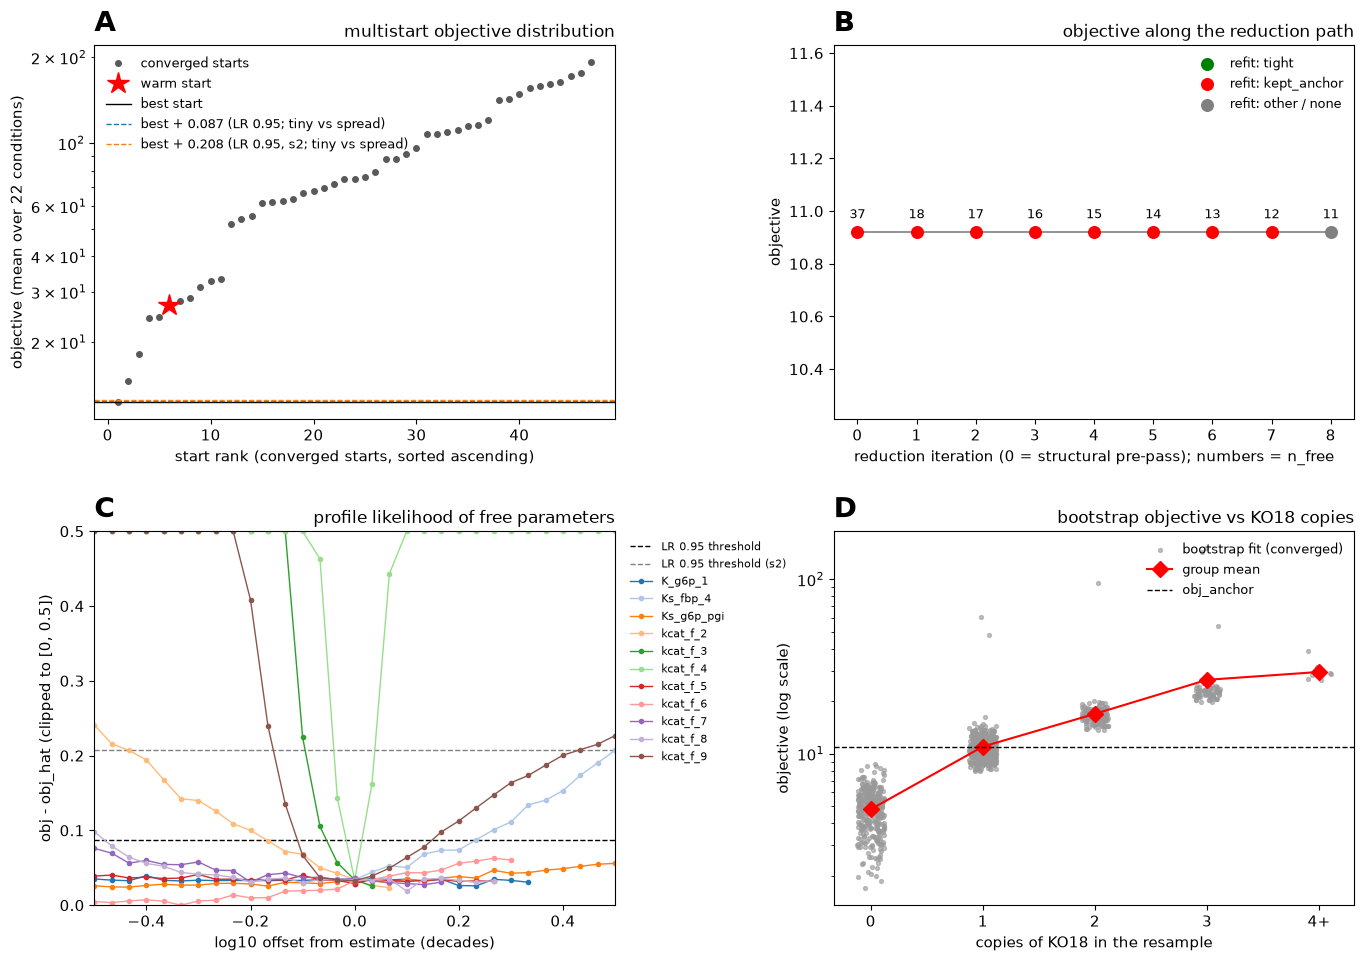

In [10]:
plt.rcdefaults()
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "legend.frameon": False,
                     "axes.prop_cycle": cycler(color=plt.cm.tab20.colors)})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.subplots_adjust(left=0.07, right=0.97, bottom=0.07, top=0.93, wspace=0.42, hspace=0.3)
ax_a = axes[0, 0]
ax_b = axes[0, 1]
ax_c = axes[1, 0]
ax_d = axes[1, 1]

# Panel A: multistart objective distribution
ax_a.plot(conv_rank[~conv_warm], conv_obj[~conv_warm], "o", ms=4, color="0.35", label="converged starts")
ax_a.plot(conv_rank[conv_warm], conv_obj[conv_warm], "*", ms=16, color="red", label="warm start")
ax_a.axhline(best, color="black", lw=1, label="best start")
ax_a.axhline(best + profile_thr["lr_threshold_0.95"], color="tab:blue", ls="--", lw=1,
             label="best + %.3f (LR 0.95; tiny vs spread)" % profile_thr["lr_threshold_0.95"])
ax_a.axhline(best + profile_thr["lr_threshold_0.95_s2"], color="tab:orange", ls="--", lw=1,
             label="best + %.3f (LR 0.95, s2; tiny vs spread)" % profile_thr["lr_threshold_0.95_s2"])
ax_a.set_yscale("log")
ax_a.set_xlabel("start rank (converged starts, sorted ascending)")
ax_a.set_ylabel("objective (mean over 22 conditions)")
ax_a.legend(fontsize=9, loc="upper left")
ax_a.set_title("multistart objective distribution", loc="right")
ax_a.text(0.0, 1.02, "A", transform=ax_a.transAxes, fontsize=20, fontweight="bold", ha="left", va="bottom")

# Panel B: objective along the reduction path
ax_b.plot(it_iter, it_y, drawstyle="steps-post", color="0.5", lw=1.2, zorder=1)
ax_b.scatter(it_iter[is_tight], it_y[is_tight], s=70, color="green", zorder=3, label="refit: tight")
ax_b.scatter(it_iter[is_kept], it_y[is_kept], s=70, color="red", zorder=3, label="refit: kept_anchor")
ax_b.scatter(it_iter[is_other], it_y[is_other], s=70, color="grey", zorder=3, label="refit: other / none")
for k in range(len(it_iter)):
    ax_b.annotate("%d" % it_nfree[k], (it_iter[k], it_y[k]), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)

ax_b.margins(y=0.15)
ax_b.set_xticks(it_iter)
ax_b.set_xlabel("reduction iteration (0 = structural pre-pass); numbers = n_free")
ax_b.set_ylabel("objective")
ax_b.legend(fontsize=9, loc="upper right")
ax_b.set_title("objective along the reduction path", loc="right")
ax_b.text(0.0, 1.02, "B", transform=ax_b.transAxes, fontsize=20, fontweight="bold", ha="left", va="bottom")

# Panel C: profiles of all free parameters on one axis
ax_c.axhline(profile_thr["lr_threshold_0.95"], color="black", ls="--", lw=1, label="LR 0.95 threshold")
ax_c.axhline(profile_thr["lr_threshold_0.95_s2"], color="grey", ls="--", lw=1, label="LR 0.95 threshold (s2)")
for param in prof_sorted["param"].unique():
    sub = prof_sorted[prof_sorted["param"] == param]
    ax_c.plot(sub["log10_offset"], np.clip(sub["obj"] - profile_thr["obj_hat"], 0.0, 0.5), "o-", ms=3, lw=1, label=param)

ax_c.set_xlim(-0.5, 0.5)
ax_c.set_ylim(0.0, 0.5)
ax_c.set_xlabel("log10 offset from estimate (decades)")
ax_c.set_ylabel("obj - obj_hat (clipped to [0, 0.5])")
ax_c.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax_c.set_title("profile likelihood of free parameters", loc="right")
ax_c.text(0.0, 1.02, "C", transform=ax_c.transAxes, fontsize=20, fontweight="bold", ha="left", va="bottom")

# Panel D: bootstrap objective versus KO18 copies in the resample
ax_d.scatter(boot_jit, boot_l["obj"].values, s=8, color="0.6", alpha=0.6, label="bootstrap fit (converged)")
ax_d.plot(boot_mean.index.values, boot_mean.values, "D-", color="red", ms=8, lw=1.5, label="group mean")
ax_d.axhline(profile_thr["obj_anchor"], color="black", ls="--", lw=1, label="obj_anchor")
ax_d.set_yscale("log")
ax_d.set_xticks([0, 1, 2, 3, 4])
ax_d.set_xticklabels(["0", "1", "2", "3", "4+"])
ax_d.set_xlabel("copies of KO18 in the resample")
ax_d.set_ylabel("objective (log scale)")
ax_d.legend(fontsize=9, loc="upper right")
ax_d.set_title("bootstrap objective vs KO18 copies", loc="right")
ax_d.text(0.0, 1.02, "D", transform=ax_d.transAxes, fontsize=20, fontweight="bold", ha="left", va="bottom")

if WRITABLE:
    fig.savefig(os.path.join(FIG, "landscape.png"), dpi=200, bbox_inches="tight")
    fig.savefig(os.path.join(FIG, "landscape.pdf"), bbox_inches="tight")

plt.show()

## Pipeline diagram (`pipeline_diagram`)

Flow diagram of the selection: data and bounds, stage 0, the reduction loop (structural check, structural fix, practical analysis, the first rule that fires, refit), convergence, the final structure with its uncertainty and validation steps, and the outcome. The counts and thresholds in the boxes are read from the results and the settings.

In [11]:
# ---- numbers of the boxes ----

def exp10(x):
    """LaTeX power of ten of x, e.g. 1e-08 -> 10^{-8}."""
    return "10^{%d}" % int(round(np.log10(x)))

n_start_stage0 = THRESHOLDS["n_starts_stage0"]
n_profile_points = 0
for _param, offsets in profiles_all.groupby("param")["log10_offset"]:
    n_profile_points = max(n_profile_points, int(offsets.round(6).nunique()))
profile_span = float(profiles_all["log10_offset"].abs().max())
lr_thr_txt = "%.3f" % final_summary["lr_threshold_0.95"]
rule_box = {"R0": n_rule("zero_influence"), "R1": n_rule("svd"), "R2": n_rule("corr"), "R3": n_rule("flag")}
fixed_parts = [("%d rate-level exact" % n_rule("structural_exact", "structural_mixed"), n_rule("structural_exact", "structural_mixed")),
               ("%d point-dependent" % n_rule("structural_pointdep"), n_rule("structural_pointdep")),
               ("%d output-level" % n_rule("structural_output"), n_rule("structural_output")),
               ("%d zero influence" % n_rule("zero_influence"), n_rule("zero_influence")),
               ("%d SVD" % n_rule("svd"), n_rule("svd")), ("%d correlation" % n_rule("corr"), n_rule("corr")),
               ("%d flag" % n_rule("flag"), n_rule("flag"))]
fixed_txt = " + ".join(t for t, n in fixed_parts if n)
print(fixed_txt)

8 rate-level exact + 1 point-dependent + 10 output-level + 5 SVD + 1 correlation + 1 flag


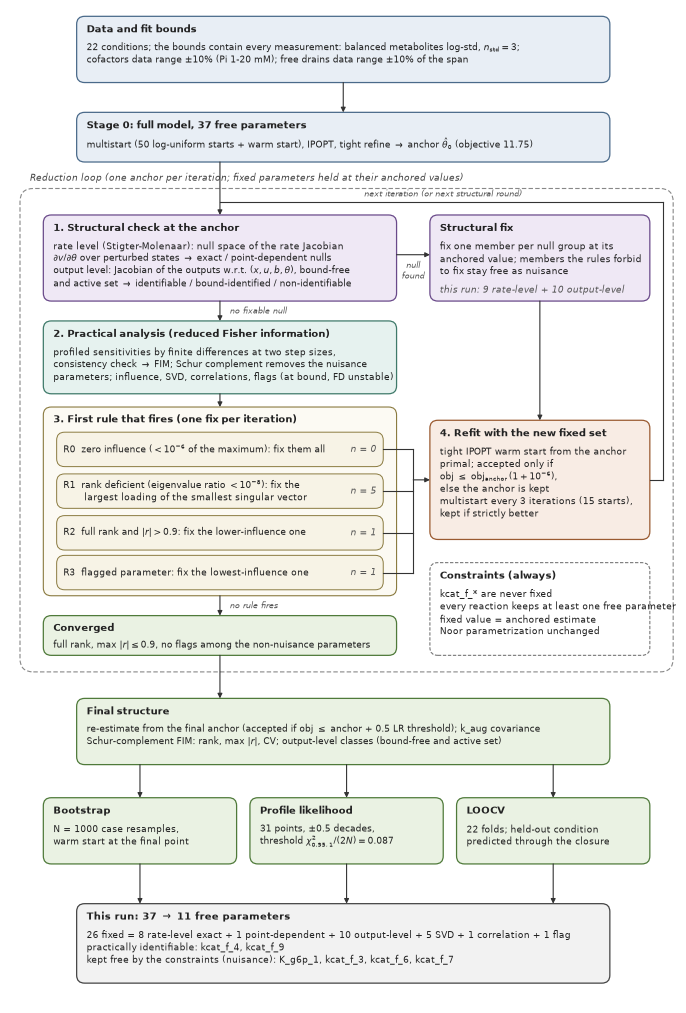

In [12]:
plt.rcdefaults()
plt.rcParams.update({"font.family": "sans-serif", "font.size": 6.6, "mathtext.fontset": "dejavusans"})

C_DATA = ("#E8EEF5", "#4A6A8A")
C_STRUCT = ("#EFE8F5", "#6A4A8A")
C_PRACT = ("#E6F2EF", "#3F7A6A")
C_RULE = ("#F7F3E6", "#8A7A3F")
C_REFIT = ("#F8ECE4", "#9A5A30")
C_FINAL = ("#EAF2E3", "#4F7A3A")
C_OUT = ("#F2F2F2", "#444444")
ROUND = "round,pad=0,rounding_size=1.2"
ARROW = dict(arrowstyle="-|>", color="#333333", lw=0.8, shrinkA=0, shrinkB=0, mutation_scale=7)
LINE = dict(color="#333333", lw=0.8)
TITLE = dict(fontsize=7.5, fontweight="bold", va="top", ha="left", color="#222222")
BODY = dict(fontsize=6.6, va="top", ha="left", color="#222222", linespacing=1.35)
NOTE = dict(fontsize=6.2, va="top", ha="left", color="#555555", style="italic", linespacing=1.35)
LABEL = dict(fontsize=6.0, color="#555555", style="italic")

fig, ax = plt.subplots(figsize=(8.6, 12.9))
ax.set_xlim(0, 100)
ax.set_ylim(0, 150)
ax.axis("off")

# ---- data and bounds ----
ax.add_patch(FancyBboxPatch((10, 139), 80, 10, boxstyle=ROUND, fc=C_DATA[0], ec=C_DATA[1], lw=0.9))
ax.text(11.5, 147.8, "Data and fit bounds", **TITLE)
ax.text(11.5, 145.2, "%d conditions; the bounds contain every measurement: balanced metabolites log-std, "
        "$n_{\\mathrm{std}} = %g$;\ncofactors data range $\\pm$%d%% (Pi %g-%g mM); free drains data range "
        "$\\pm$%d%% of the span" % (len(folds), BOUNDS_RULES["n_std"], round(100 * BOUNDS_RULES["cofactor_slack"]),
                                    BOUNDS_RULES["pi_lo"], BOUNDS_RULES["pi_hi"], round(100 * BOUNDS_RULES["drain_widen"])), **BODY)

# ---- stage 0 ----
ax.annotate("", xy=(50, 134.5), xytext=(50, 139), arrowprops=ARROW)
ax.add_patch(FancyBboxPatch((10, 127), 80, 7.5, boxstyle=ROUND, fc=C_DATA[0], ec=C_DATA[1], lw=0.9))
ax.text(11.5, 133.3, "Stage 0: full model, %d free parameters" % len(ALL_PARAMS), **TITLE)
ax.text(11.5, 130.7, "multistart (%d log-uniform starts + warm start), IPOPT, tight refine $\\rightarrow$ "
        "anchor $\\hat{\\theta}_0$ (objective %.2f)" % (n_start_stage0, stage_row["obj"]), **BODY)

# ---- reduction loop frame ----
ax.add_patch(FancyBboxPatch((1.5, 50), 98, 73, boxstyle="round,pad=0,rounding_size=2", fc="none", ec="#888888", lw=0.8, ls=(0, (4, 2))))
ax.text(3, 124.6, "Reduction loop (one anchor per iteration; fixed parameters held at their anchored values)",
        fontsize=6.8, style="italic", color="#444444", va="center", ha="left")
ax.annotate("", xy=(31.5, 119), xytext=(31.5, 127), arrowprops=ARROW)

# ---- 1. structural check ----
ax.add_patch(FancyBboxPatch((5, 106), 53, 13, boxstyle=ROUND, fc=C_STRUCT[0], ec=C_STRUCT[1], lw=0.9))
ax.text(6.5, 117.8, "1. Structural check at the anchor", **TITLE)
ax.text(6.5, 115.2, "rate level (Stigter-Molenaar): null space of the rate Jacobian\n"
        "$\\partial v / \\partial \\theta$ over perturbed states $\\rightarrow$ exact / point-dependent nulls\n"
        "output level: Jacobian of the outputs w.r.t. $(x, u, b, \\theta)$, bound-free\n"
        "and active set $\\rightarrow$ identifiable / bound-identified / non-identifiable", **BODY)

# ---- structural fix ----
ax.annotate("", xy=(63, 113), xytext=(58, 113), arrowprops=ARROW)
ax.text(60.5, 112.2, "null\nfound", ha="center", va="top", **LABEL)
ax.add_patch(FancyBboxPatch((63, 106), 33, 13, boxstyle=ROUND, fc=C_STRUCT[0], ec=C_STRUCT[1], lw=0.9))
ax.text(64.5, 117.8, "Structural fix", **TITLE)
ax.text(64.5, 115.2, "fix one member per null group at its\nanchored value; members the rules forbid\nto fix stay free as nuisance", **BODY)
ax.text(64.5, 108.6, "this run: %d rate-level + %d output-level" % (n_rule("structural_exact", "structural_mixed", "structural_pointdep"), n_rule("structural_output")), **NOTE)

# ---- 2. practical analysis ----
ax.annotate("", xy=(31.5, 103), xytext=(31.5, 106), arrowprops=ARROW)
ax.text(33, 104.5, "no fixable null", ha="left", va="center", **LABEL)
ax.add_patch(FancyBboxPatch((5, 92), 53, 11, boxstyle=ROUND, fc=C_PRACT[0], ec=C_PRACT[1], lw=0.9))
ax.text(6.5, 101.8, "2. Practical analysis (reduced Fisher information)", **TITLE)
ax.text(6.5, 99.2, "profiled sensitivities by finite differences at two step sizes,\n"
        "consistency check $\\rightarrow$ FIM; Schur complement removes the nuisance\n"
        "parameters; influence, SVD, correlations, flags (at bound, FD unstable)", **BODY)

# ---- 3. rules ----
ax.annotate("", xy=(31.5, 90), xytext=(31.5, 92), arrowprops=ARROW)
ax.add_patch(FancyBboxPatch((5, 61.5), 53, 28.5, boxstyle=ROUND, fc="#FCFAF3", ec=C_RULE[1], lw=0.8))
ax.text(6.5, 88.9, "3. First rule that fires (one fix per iteration)", **TITLE)
ax.add_patch(FancyBboxPatch((7, 81), 49, 5.2, boxstyle=ROUND, fc=C_RULE[0], ec=C_RULE[1], lw=0.7))
ax.text(8, 83.6, "R0  zero influence ($< %s$ of the maximum): fix them all" % exp10(THRESHOLDS["zero_cut"]), fontsize=6.6, va="center", ha="left", color="#222222")
ax.text(55, 83.6, "n = %d" % rule_box["R0"], fontsize=6.2, ha="right", va="center", color="#555555", style="italic")
ax.add_patch(FancyBboxPatch((7, 74.7), 49, 5.2, boxstyle=ROUND, fc=C_RULE[0], ec=C_RULE[1], lw=0.7))
ax.text(8, 77.3, "R1  rank deficient (eigenvalue ratio $< %s$): fix the\n       largest loading of the smallest singular vector" % exp10(THRESHOLDS["eig_cut"]),
        fontsize=6.6, va="center", ha="left", color="#222222", linespacing=1.35)
ax.text(55, 77.3, "n = %d" % rule_box["R1"], fontsize=6.2, ha="right", va="center", color="#555555", style="italic")
ax.add_patch(FancyBboxPatch((7, 68.4), 49, 5.2, boxstyle=ROUND, fc=C_RULE[0], ec=C_RULE[1], lw=0.7))
ax.text(8, 71.0, "R2  full rank and $|r| > %g$: fix the lower-influence one" % THRESHOLDS["corr_threshold"], fontsize=6.6, va="center", ha="left", color="#222222")
ax.text(55, 71.0, "n = %d" % rule_box["R2"], fontsize=6.2, ha="right", va="center", color="#555555", style="italic")
ax.add_patch(FancyBboxPatch((7, 62.4), 49, 5.2, boxstyle=ROUND, fc=C_RULE[0], ec=C_RULE[1], lw=0.7))
ax.text(8, 65.0, "R3  flagged parameter: fix the lowest-influence one", fontsize=6.6, va="center", ha="left", color="#222222")
ax.text(55, 65.0, "n = %d" % rule_box["R3"], fontsize=6.2, ha="right", va="center", color="#555555", style="italic")

# ---- bus from the rules to the refit ----
ax.plot([56, 60.5], [83.6, 83.6], **LINE)
ax.plot([56, 60.5], [77.3, 77.3], **LINE)
ax.plot([56, 60.5], [71.0, 71.0], **LINE)
ax.plot([56, 60.5], [65.0, 65.0], **LINE)
ax.plot([60.5, 60.5], [65.0, 83.6], **LINE)
ax.annotate("", xy=(63, 79), xytext=(60.5, 79), arrowprops=ARROW)

# ---- 4. refit ----
ax.annotate("", xy=(79.5, 88), xytext=(79.5, 106), arrowprops=ARROW)
ax.add_patch(FancyBboxPatch((63, 70), 33, 18, boxstyle=ROUND, fc=C_REFIT[0], ec=C_REFIT[1], lw=0.9))
ax.text(64.5, 86.8, "4. Refit with the new fixed set", **TITLE)
ax.text(64.5, 84.2, "tight IPOPT warm start from the anchor\nprimal; accepted only if\n"
        "obj $\\leq$ obj$_{\\mathrm{anchor}}\\,(1 + %s)$,\nelse the anchor is kept\n"
        "multistart every %d iterations (%d starts),\nkept if strictly better" % (exp10(THRESHOLDS["refit_rtol"]), THRESHOLDS["multistart_every"], THRESHOLDS["n_starts"]), **BODY)

# ---- return path: next iteration ----
ax.plot([96, 98], [79, 79], **LINE)
ax.plot([98, 98], [79, 121], **LINE)
ax.plot([98, 31.5], [121, 121], **LINE)
ax.text(65, 121.5, "next iteration (or next structural round)", ha="center", va="bottom", **LABEL)

# ---- selection rules (apply throughout) ----
ax.add_patch(FancyBboxPatch((63, 52.5), 33, 14, boxstyle=ROUND, fc="#FFFFFF", ec="#777777", lw=0.8, ls=(0, (3, 1.5))))
ax.text(64.5, 65.3, "Constraints (always)", **TITLE)
ax.text(64.5, 62.7, "kcat_f_* are never fixed\nevery reaction keeps at least one free parameter\n"
        "fixed value = anchored estimate\nNoor parametrization unchanged", **BODY)

# ---- converged ----
ax.annotate("", xy=(31.5, 58.5), xytext=(31.5, 61.5), arrowprops=ARROW)
ax.text(33, 60, "no rule fires", ha="left", va="center", **LABEL)
ax.add_patch(FancyBboxPatch((5, 52.5), 53, 6, boxstyle=ROUND, fc=C_FINAL[0], ec=C_FINAL[1], lw=0.9))
ax.text(6.5, 57.4, "Converged", **TITLE)
ax.text(6.5, 54.9, "full rank, max $|r| \\leq %g$, no flags among the non-nuisance parameters" % THRESHOLDS["corr_threshold"], **BODY)

# ---- final structure ----
ax.annotate("", xy=(31.5, 46), xytext=(31.5, 52.5), arrowprops=ARROW)
ax.add_patch(FancyBboxPatch((10, 36), 80, 10, boxstyle=ROUND, fc=C_FINAL[0], ec=C_FINAL[1], lw=0.9))
ax.text(11.5, 44.8, "Final structure", **TITLE)
ax.text(11.5, 42.2, "re-estimate from the final anchor (accepted if obj $\\leq$ anchor + %g LR threshold); k_aug covariance\n"
        "Schur-complement FIM: rank, max $|r|$, CV; output-level classes (bound-free and active set)" % THRESHOLDS["final_accept_lr_fraction"], **BODY)

# ---- uncertainty and validation ----
ax.annotate("", xy=(19.5, 31), xytext=(19.5, 36), arrowprops=ARROW)
ax.annotate("", xy=(50.5, 31), xytext=(50.5, 36), arrowprops=ARROW)
ax.annotate("", xy=(81.5, 31), xytext=(81.5, 36), arrowprops=ARROW)
ax.add_patch(FancyBboxPatch((5, 21), 29, 10, boxstyle=ROUND, fc=C_FINAL[0], ec=C_FINAL[1], lw=0.9))
ax.text(6.5, 29.8, "Bootstrap", **TITLE)
ax.text(6.5, 27.2, "N = %d case resamples,\nwarm start at the final point" % boot_info["n_resamples"], **BODY)
ax.add_patch(FancyBboxPatch((36, 21), 29, 10, boxstyle=ROUND, fc=C_FINAL[0], ec=C_FINAL[1], lw=0.9))
ax.text(37.5, 29.8, "Profile likelihood", **TITLE)
ax.text(37.5, 27.2, "%d points, $\\pm$%g decades,\nthreshold $\\chi^2_{0.95,1} / (2N) = %s$" % (n_profile_points, profile_span, lr_thr_txt), **BODY)
ax.add_patch(FancyBboxPatch((67, 21), 29, 10, boxstyle=ROUND, fc=C_FINAL[0], ec=C_FINAL[1], lw=0.9))
ax.text(68.5, 29.8, "LOOCV", **TITLE)
ax.text(68.5, 27.2, "%d folds; held-out condition\npredicted through the closure" % len(folds), **BODY)

# ---- outcome ----
ax.annotate("", xy=(19.5, 15), xytext=(19.5, 21), arrowprops=ARROW)
ax.annotate("", xy=(50.5, 15), xytext=(50.5, 21), arrowprops=ARROW)
ax.annotate("", xy=(81.5, 15), xytext=(81.5, 21), arrowprops=ARROW)
ax.add_patch(FancyBboxPatch((10, 3), 80, 12, boxstyle=ROUND, fc=C_OUT[0], ec=C_OUT[1], lw=0.9))
ax.text(11.5, 13.8, "This run: %d $\\rightarrow$ %d free parameters" % (len(ALL_PARAMS), len(FREE)), **TITLE)
ax.text(11.5, 11.2, "%d fixed = %s\npractically identifiable: %s\nkept free by the constraints (nuisance): %s" % (
    len(ALL_PARAMS) - len(FREE), fixed_txt, ", ".join(identifiable) or "none", ", ".join(nuisance) or "none"), **BODY)

if WRITABLE:
    fig.savefig(os.path.join(FIG, "pipeline_diagram.png"), dpi=300, bbox_inches="tight")
    fig.savefig(os.path.join(FIG, "pipeline_diagram.pdf"), bbox_inches="tight")

plt.show()

## Fixing path (`fixing_path`)

Each fixed parameter by step and rule (a), the number of free parameters (b), the objective of the accepted anchor and of the best rejected refit (c), the smallest singular ratio of the reduced FIM before each practical fix (d) and the largest correlation (e). A *step* is one structural round of iteration 0 (labelled `0.r`) or one practical iteration. The objective after each step and the rejected refits are read from `reduction/reduction.log`, matched to the steps by the number of free parameters.

In [13]:
# ---- steps of the path ----
fix = fix_log.copy()
fix["is_struct"] = fix["stage"].eq("structural") if "stage" in fix.columns else fix["iter"].eq(0)
fix["round_key"] = fix["round"].fillna(-1)
step_keys = list(dict.fromkeys(zip(fix["iter"], fix["round_key"])))
step_index = {k: i + 1 for i, k in enumerate(step_keys)}
fix["step"] = [step_index[k] for k in zip(fix["iter"], fix["round_key"])]
fix["order"] = np.arange(len(fix))
n_struct_steps = len({step_index[k] for k, s in zip(zip(fix["iter"], fix["round_key"]), fix["is_struct"]) if s})
labels = ["stage 0"]
for (it, rnd) in step_keys:
    is_s = bool(fix.loc[(fix["iter"] == it) & (fix["round_key"] == rnd), "is_struct"].iloc[0])
    labels.append("%d.%d" % (it, int(rnd)) if is_s else "%d" % it)

last_iter = int(iterations["iter"].max())
converged_step = None
if last_iter > 0 and not (fix["iter"] == last_iter).any():
    converged_step = len(labels)
    labels.append("%d" % last_iter)

final_step = len(labels)
labels.append("final")
steps = np.arange(len(labels))

n_free_path = [len(ALL_PARAMS)]
for s in range(1, len(step_keys) + 1):
    n_free_path.append(n_free_path[-1] - int((fix["step"] == s).sum()))

free_to_step = {n_free_path[s]: s for s in range(1, len(step_keys) + 1)}

obj_anchor = {0: float(iterations.loc[iterations["iter"] == 0, "obj_start"].iloc[0])}
obj_rejected = {}
last_tight = None
for line in open(path("reduction", "reduction.log")):
    mt = re.search(r"refit attempt 'tight': obj ([0-9.]+) .*(accepted|REJECTED)", line)
    if mt:
        last_tight = (float(mt.group(1)), mt.group(2))
        continue
    mr = re.search(r"refit: (\d+) free, (?:obj_before [0-9.]+ -> obj_after|obj) ([0-9.]+)", line) or re.search(r"structural refit: (\d+) free, obj ([0-9.]+)", line)
    if mr and int(mr.group(1)) in free_to_step:
        s = free_to_step[int(mr.group(1))]
        obj_anchor[s] = float(mr.group(2))
        if last_tight is not None and last_tight[1] == "REJECTED":
            obj_rejected[s] = last_tight[0]
        last_tight = None

for s in range(1, len(step_keys) + 1):
    obj_anchor.setdefault(s, obj_anchor[s - 1])

if converged_step is not None:
    obj_anchor[converged_step] = obj_anchor[converged_step - 1]

obj_anchor[final_step] = float(final_summary["obj_re_estimated"])
obj_x = sorted(obj_anchor)
obj_y = [obj_anchor[s] for s in obj_x]
rej_x = sorted(obj_rejected)
rej_y = [obj_rejected[s] for s in rej_x]
lr_thr = float(final_summary.get("lr_threshold_0.95", lr_threshold(THRESHOLDS["lr_alpha"], len(real))))
best_step = obj_x[0]
for s in obj_x:
    if obj_anchor[s] < obj_anchor[best_step]:
        best_step = s

# practical triggers at the analysis that starts each practical iteration
prac = iterations[iterations["iter"] >= 1].copy()
prac_step = {}
for (it, rnd), s in step_index.items():
    if not bool(fix.loc[fix["step"] == s, "is_struct"].iloc[0]):
        prac_step.setdefault(int(it), s)

prac["step"] = [prac_step.get(int(i), converged_step if converged_step is not None else final_step - 1) for i in prac["iter"]]
sv_cut = float(np.sqrt(prac["eig_cut"].dropna().iloc[0]))
print("steps:", labels)
print("free count:", n_free_path)

steps: ['stage 0', '0.0', '0.1', '0.2', '1', '2', '3', '4', '5', '6', '7', '8', 'final']
free count: [37, 29, 28, 18, 17, 16, 15, 14, 13, 12, 11]


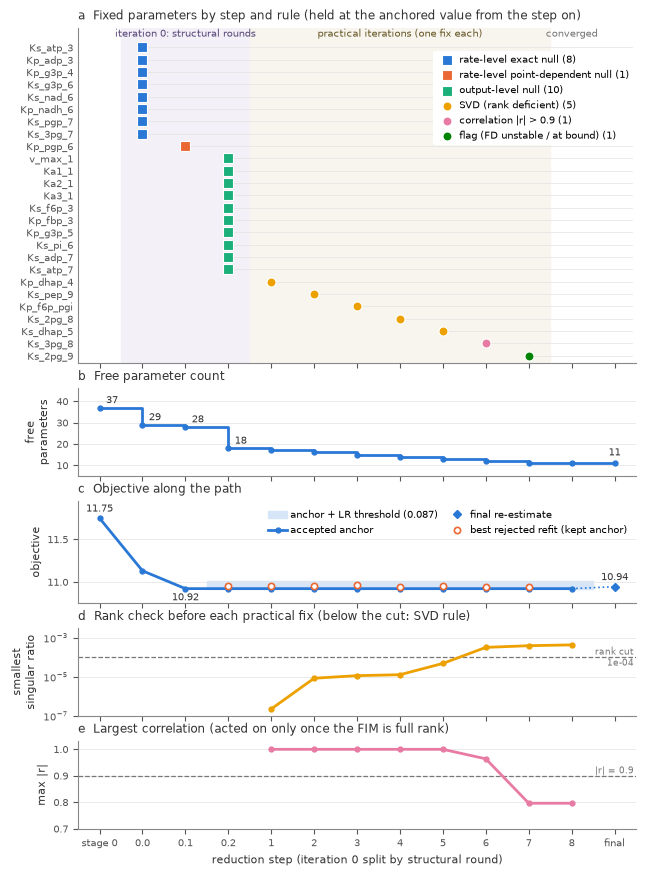

In [14]:
plt.rcdefaults()
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
                     "legend.fontsize": 7, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#888888",
                     "xtick.color": "#555555", "ytick.color": "#555555", "axes.labelcolor": "#333333", "pdf.fonttype": 42})

RULES = [
    ("structural_exact", "rate-level exact null", "#2a78d6", "s"),
    ("structural_pointdep", "rate-level point-dependent null", "#eb6834", "s"),
    ("structural_output", "output-level null", "#1baf7a", "s"),
    ("zero_influence", "zero influence", "#9a9a9a", "o"),
    ("svd", "SVD (rank deficient)", "#eda100", "o"),
    ("corr", "correlation |r| > %g" % THRESHOLDS["corr_threshold"], "#e87ba4", "o"),
    ("flag", "flag (FD unstable / at bound)", "#008300", "o"),
]
INK = "#333333"
MUTED = "#777777"
GRID = "#e6e6e6"

fig, (ax_a, ax_b, ax_c, ax_d, ax_e) = plt.subplots(
    5, 1, figsize=(7.2, 10.4), sharex=True, gridspec_kw={"height_ratios": [4.6, 1.2, 1.4, 1.2, 1.2], "hspace": 0.18})

# ---- (a) fixed parameters by step and rule ----
x_end = len(labels) - 0.6
ax_a.axvspan(0.5, n_struct_steps + 0.5, color="#f3f0f8", zorder=0)
ax_a.axvspan(n_struct_steps + 0.5, len(step_keys) + 0.5, color="#f7f5ee", zorder=0)
for key, label, color, marker in RULES:
    sub = fix[fix["rule"] == key]
    if len(sub):
        ax_a.scatter(sub["step"], sub["order"], s=42, c=color, marker=marker, edgecolors="white", linewidths=0.8, zorder=3, label="%s (%d)" % (label, len(sub)))

for _, r in fix.iterrows():
    ax_a.plot([r["step"], x_end], [r["order"], r["order"]], color=GRID, lw=0.6, zorder=1)

ax_a.set_yticks(fix["order"])
ax_a.set_yticklabels(fix["param"])
ax_a.set_ylim(len(fix) - 0.4, -1.6)
ax_a.text((0.5 + n_struct_steps + 0.5) / 2, -1.1, "iteration 0: structural rounds", ha="center", va="center", fontsize=7.5, color="#5a4a7a")
ax_a.text((n_struct_steps + 0.5 + len(step_keys) + 0.5) / 2, -1.1, "practical iterations (one fix each)", ha="center", va="center", fontsize=7.5, color="#6a5a2a")
if converged_step is not None:
    ax_a.text(converged_step, -1.1, "converged", ha="center", va="center", fontsize=7.5, color=MUTED)

ax_a.set_title("a  Fixed parameters by step and rule (held at the anchored value from the step on)", loc="left", color=INK)
leg = ax_a.legend(loc="upper right", bbox_to_anchor=(1.0, 0.94), frameon=True, handletextpad=0.3, borderaxespad=0.3)
leg.get_frame().set_facecolor("white")
leg.get_frame().set_edgecolor("none")
leg.get_frame().set_alpha(1.0)
ax_a.tick_params(axis="y", length=0)

# ---- (b) free parameter count ----
ax_b.step(steps, n_free_path + [n_free_path[-1]] * (len(steps) - len(n_free_path)), where="post", color="#2a78d6", lw=2)
ax_b.plot(steps, n_free_path + [n_free_path[-1]] * (len(steps) - len(n_free_path)), "o", color="#2a78d6", ms=3.5)
for s in [0] + [step_index[k] for k in step_keys if bool(fix.loc[fix["step"] == step_index[k], "is_struct"].iloc[0])]:
    ax_b.text(s + 0.15, n_free_path[s] + 1.0, "%d" % n_free_path[s], ha="left", va="bottom", fontsize=7, color=INK)

ax_b.text(final_step, n_free_path[-1] + 2.5, "%d" % len(FREE), ha="center", va="bottom", fontsize=7, color=INK)
ax_b.set_ylim(len(FREE) - 6, len(ALL_PARAMS) + 9)
ax_b.set_yticks(range(10, len(ALL_PARAMS) + 4, 10))
ax_b.set_ylabel("free\nparameters")
ax_b.grid(axis="y", color=GRID, lw=0.6)
ax_b.set_title("b  Free parameter count", loc="left", color=INK)

# ---- (c) objective along the path ----
ax_c.fill_between([best_step + 0.5, len(steps) - 1.5], obj_anchor[best_step], obj_anchor[best_step] + lr_thr, color="#d6e6f8", zorder=0,
                  label="anchor + LR threshold (%.3f)" % lr_thr)
ax_c.plot(obj_x[:-1], obj_y[:-1], "-o", color="#2a78d6", lw=2, ms=3.5, zorder=3, label="accepted anchor")
ax_c.plot([obj_x[-2], obj_x[-1]], [obj_y[-2], obj_y[-1]], ":", color="#2a78d6", lw=1.2, zorder=2)
ax_c.plot(obj_x[-1], obj_y[-1], "D", color="#2a78d6", ms=4.5, zorder=3, label="final re-estimate")
if rej_x:
    ax_c.plot(rej_x, rej_y, "o", mfc="white", mec="#eb6834", mew=1.2, ms=4.5, zorder=3, label="best rejected refit (kept anchor)")

ax_c.text(0, obj_y[0] + 0.05, "%.2f" % obj_y[0], ha="center", va="bottom", fontsize=7, color=INK)
ax_c.text(best_step, obj_anchor[best_step] - 0.05, "%.2f" % obj_anchor[best_step], ha="center", va="top", fontsize=7, color=INK)
ax_c.text(final_step, obj_y[-1] + 0.05, "%.2f" % obj_y[-1], ha="center", va="bottom", fontsize=7, color=INK)
ax_c.set_ylim(min(obj_y + rej_y) - 0.17, max(obj_y + rej_y) + 0.2)
ax_c.set_ylabel("objective")
ax_c.grid(axis="y", color=GRID, lw=0.6)
ax_c.legend(loc="upper right", frameon=False, ncol=2, handletextpad=0.3, columnspacing=1.0)
ax_c.set_title("c  Objective along the path", loc="left", color=INK)

# ---- (d) smallest singular ratio of the reduced FIM (Schur complement) ----
ax_d.axhline(sv_cut, color=MUTED, lw=0.9, ls="--")
ax_d.text(len(labels) - 0.55, sv_cut, "rank cut\n%.0e" % sv_cut, ha="right", va="center", fontsize=6.5, color=MUTED)
ax_d.plot(prac["step"], prac["sigma_ratio"], "-o", color="#eda100", lw=2, ms=3.5)
ax_d.set_yscale("log")
ax_d.set_ylim(10.0 ** np.floor(np.log10(prac["sigma_ratio"].min())), max(prac["sigma_ratio"].max(), sv_cut) * 7)
ax_d.set_ylabel("smallest\nsingular ratio")
ax_d.grid(axis="y", color=GRID, lw=0.6)
ax_d.set_title("d  Rank check before each practical fix (below the cut: SVD rule)", loc="left", color=INK)

# ---- (e) largest |r| among the non-nuisance free parameters ----
ax_e.axhline(THRESHOLDS["corr_threshold"], color=MUTED, lw=0.9, ls="--")
ax_e.text(len(labels) - 0.55, THRESHOLDS["corr_threshold"], "|r| = %g" % THRESHOLDS["corr_threshold"], ha="right", va="bottom", fontsize=6.5, color=MUTED)
ax_e.plot(prac["step"], prac["max_abs_r"], "-o", color="#e87ba4", lw=2, ms=3.5)
ax_e.set_ylim(max(0.0, np.floor((min(prac["max_abs_r"].min(), 0.85) - 0.02) * 10) / 10), 1.03)
ax_e.set_ylabel("max |r|")
ax_e.grid(axis="y", color=GRID, lw=0.6)
ax_e.set_title("e  Largest correlation (acted on only once the FIM is full rank)", loc="left", color=INK)
ax_e.set_xticks(steps)
ax_e.set_xticklabels(labels)
ax_e.set_xlim(-0.5, len(labels) - 0.5)
ax_e.set_xlabel("reduction step (iteration 0 split by structural round)")

if WRITABLE:
    fig.savefig(os.path.join(FIG, "fixing_path.png"), dpi=300, bbox_inches="tight")
    fig.savefig(os.path.join(FIG, "fixing_path.pdf"), bbox_inches="tight")

plt.show()